# Llevar una curva de PD a un año nuevo: PD escaladas, razón de verosimilitud escalada y QMM

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (una PD por grado y el promedio de largo plazo)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué es un modelo de calificación como distribución conjunta de grado e incumplimiento, y verificar las identidades de Tasche entre la curva de PD, el perfil de calificación y el perfil de incumplimiento en un modelo real;
- suavizar una curva de PD con ajuste cuasi de momentos (QMM) y decir por qué una curva con ceros no se puede usar tal cual;
- llevar una curva de PD de un año de estimación a un año de pronóstico con los cuatro enfoques que conocen el perfil y la PD del pronóstico: perfil de incumplimiento invariante, razón de precisión invariante, PD escaladas, razón de verosimilitud escalada, cada uno con sus constantes impresas;
- decir qué agregan los casos en que solo se conoce la PD, o solo el perfil, y por qué llevar la curva vieja sin cambios es la elección más costosa;
- leer la prueba chi-cuadrado del perfil de incumplimiento implicado, y poner precio a la elección en ponderador de riesgo IRB.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import capital_requirement

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C05, la calibración de una curva de PD sobre las calificaciones corporativas de S&P de Tasche (2013) (clase de licencia `derived-only`: el artefacto guarda el perfil de calificación, la tasa de incumplimiento por grado y los resultados, nunca los conteos por grado, así que ningún cuaderno recalcula nada que necesite los conteos; https://doi.org/10.21314/jcr.2013.169):

- `data/derived/C05/sp-2010.json` y `data/derived/C05/sp-2011.json`: el modelo de estimación de 2009 (`profile0`, `default_rate0`, `default_profile0`, `pd0`, `ar0`) y el perfil y la PD del año de pronóstico (`profile1`, `pd1`) sobre 17 grados de AAA a CCC-C, la curva que da cada enfoque (`approaches`), las pruebas versionadas (`tests`), las tablas impresas de Tasche junto al recálculo (`golden`) y el impacto en capital (`impact`).
- `data/derived/C05/models-sp2009.json`: las metas del suavizado de 2009 (`fit.targets`).

La pregunta es la que enfrenta un validador cada año. Un sistema de calificación se calibró con 2009: ¿qué PD debe llevar cada grado en 2010 y en 2011? El perfil de calificación del año nuevo se conoce, y su tasa de incumplimiento también. La celda siguiente carga los archivos e imprime lo que contienen.

In [2]:
# Cargar los tres artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir lo que contienen
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
years = {2010: load("sp-2010.json"), 2011: load("sp-2011.json")}
fit2009 = load("models-sp2009.json")
o10 = years[2010]["outputs"]
grades = o10["grades"]

for label, doc in (("sp-2010", years[2010]), ("sp-2011", years[2011]), ("models-sp2009", fit2009)):
    print(f"{label:15s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("grados:", len(grades), grades[0], "...", grades[-1])
print("metas del suavizado de 2009:", fit2009["fit"]["targets"])
for yr, doc in years.items():
    o = doc["outputs"]
    print(yr, "| deudores:", o["n_obligors"], "| incumplimientos:", o["n_defaults"], "| PD del pronóstico:", round(o["pd1"], 6), "| PD de 2009:", round(o["pd0"], 6))

sp-2010         calculado con riskvalidation 0.4.3 | instalado 0.9.0
sp-2011         calculado con riskvalidation 0.4.3 | instalado 0.9.0
models-sp2009   calculado con riskvalidation 0.4.3 | instalado 0.9.0
grados: 17 AAA ... CCC-C
metas del suavizado de 2009: {'pd': 0.0399317406, 'accuracy_ratio': 0.827102342}
2010 | deudores: 5522 | incumplimientos: 63 | PD del pronóstico: 0.011409 | PD de 2009: 0.039932
2011 | deudores: 5847 | incumplimientos: 44 | PD del pronóstico: 0.007525 | PD de 2009: 0.039932


## Método

### Paso 1: un modelo de calificación es una distribución conjunta

Tasche (2013) trata un modelo de calificación como la distribución conjunta del grado $X$ de un deudor al inicio de un período y su estado $D$ (incumplimiento) o $N$ (sobrevida) al final. Tres descripciones son equivalentes: el perfil de calificación $\Pr[X = x]$ con la curva de PD $\Pr[D \mid X = x]$; la PD incondicional $p$ con los dos perfiles condicionales $\Pr[X = x \mid D]$ y $\Pr[X = x \mid N]$; o $p$ con la razón de verosimilitud $\lambda(x) = \Pr[X = x \mid N] / \Pr[X = x \mid D]$. Las identidades entre ellas son

$$p = \sum_x \Pr[D \mid X = x]\,\Pr[X = x], \qquad \Pr[X = x \mid D] = \frac{\Pr[D \mid X = x]\,\Pr[X = x]}{p}, \qquad \Pr[D \mid X = x] = \frac{p}{p + (1 - p)\,\lambda(x)}$$

(ecuaciones 3.5a, 3.5b y 3.8 del artículo). La razón de precisión $\mathrm{AR}$ del sistema de calificación se calcula con los dos perfiles condicionales (ecuación 3.7). La celda siguiente toma el modelo de 2009 del artefacto (el perfil, la tasa de incumplimiento por grado, el perfil de incumplimiento, $p$ y $\mathrm{AR}$) y verifica cada identidad con las funciones de `pd_curve` del motor.

In [3]:
# Tomar el modelo de 2009 del artefacto y verificar las identidades de Tasche con el motor
profile0 = np.array(o10["profile0"])
rate0 = np.array(o10["default_rate0"])
default_profile0 = np.array(o10["default_profile0"])
pd0, ar0 = o10["pd0"], o10["ar0"]

survival_profile0 = pc.implied_survival_profile(rate0, profile0)
print("el perfil suma uno:", si_no(np.isclose(profile0.sum(), 1.0)), "| grados con tasa de incumplimiento cero:", int((rate0 == 0).sum()), "de", len(rate0))
print("(3.5a) p =", round(pc.unconditional_pd(rate0, profile0), 6), "| versionada", round(pd0, 6))
print("(3.5b) mayor diferencia del perfil de incumplimiento:", f"{np.abs(np.array(pc.implied_default_profile(rate0, profile0)) - default_profile0).max():.1e}")
print("(3.7) AR =", round(pc.accuracy_ratio(default_profile0, survival_profile0), 6), "| versionada", round(ar0, 6))
lam0 = np.array(pc.likelihood_ratio(rate0[rate0 > 0], pd0))
print("la razón de verosimilitud no está definida donde la tasa de incumplimiento es cero; definida en", lam0.size, "grados")
print("las metas de 2009 del artefacto igualan las del modelo:", si_no(np.isclose(fit2009["fit"]["targets"]["pd"], pd0) and np.isclose(fit2009["fit"]["targets"]["accuracy_ratio"], ar0)))

el perfil suma uno: sí | grados con tasa de incumplimiento cero: 6 de 17
(3.5a) p = 0.039932 | versionada 0.039932
(3.5b) mayor diferencia del perfil de incumplimiento: 2.3e-10
(3.7) AR = 0.827102 | versionada 0.827102
la razón de verosimilitud no está definida donde la tasa de incumplimiento es cero; definida en 11 grados
las metas de 2009 del artefacto igualan las del modelo: sí


### Paso 2: suavizar la curva por ajuste cuasi de momentos

La tasa de incumplimiento cruda de 2009 es cero en seis de los 17 grados, así que una razón de verosimilitud construida con ella es cero o infinita ahí, y una PD de cero no sirve como curva. El ajuste cuasi de momentos (QMM, apéndice A de Tasche) ajusta la curva logística robusta

$$\Pr[D \mid X = x] = \frac{1}{1 + \exp\bigl(\alpha + \beta\,\Phi^{-1}(\tilde F_N(x))\bigr)}$$

con $\tilde F_N$ el promedio de la función de distribución de sobrevivientes y su versión continua por la izquierda (A.9), eligiendo $\alpha$ y $\beta$ para que la PD incondicional y la razón de precisión alcancen sus metas. La celda siguiente llama a `qmm` con el perfil, la PD, la razón de precisión y el perfil de sobrevivientes de 2009 y compara con la curva versionada.

In [4]:
# Ajustar la curva QMM a las metas de 2009 y comparar con la curva versionada
q0 = pc.qmm(profile0, pd0, ar0, survival_profile=survival_profile0)
curve0 = np.array(q0["pd_curve"])
committed_q0 = o10["qmm0"]
print("alpha =", round(q0["alpha"], 6), "| beta =", round(q0["beta"], 6), "| versionados:", round(committed_q0["alpha"], 6), round(committed_q0["beta"], 6))
print("mayor diferencia con la curva versionada:", f"{np.abs(curve0 - np.array(committed_q0['curve'])).max():.1e}")
print("la curva alcanza las metas: PD", round(pc.unconditional_pd(curve0, profile0), 6), "| AR", round(pc.accuracy_ratio_from_curve(curve0, profile0), 6))
print(f"{'grado':8s}{'tasa cruda 2009 (%)':>26s}{'curva QMM (%)':>20s}")
for g in (0, 4, 8, 12, 14, 16):
    print(f"{grades[g]:8s}{100 * rate0[g]:26.4f}{100 * curve0[g]:20.4f}")
print("la curva suavizada crece con el grado:", si_no(np.all(np.diff(curve0) > 0)))

alpha = 5.20481 | beta = 2.161269 | versionados: 5.20481 2.161269
mayor diferencia con la curva versionada: 1.3e-10
la curva alcanza las metas: PD 0.039932 | AR 0.827102
grado          tasa cruda 2009 (%)       curva QMM (%)
AAA                         0.0000              0.0028
A+                          0.2941              0.0472
BBB                         0.1848              0.4947
BB-                         0.9070              2.2800
B                           9.9585              7.9992
CCC-C                      48.4211             48.3537
la curva suavizada crece con el grado: sí


### Paso 3: llevar la curva cuando se conocen el perfil y la PD del año nuevo

Este es el caso 1 de Tasche: se conocen el perfil del pronóstico $\Pr_1[X = x]$ y la PD del pronóstico $p_1$, y la pregunta es qué parte del modelo queda como estaba. Cada enfoque es un supuesto sobre qué es invariante:

- **Perfil de incumplimiento invariante** (ecuación 4.2): $\Pr_1[X = x \mid D] = \Pr_0[X = x \mid D]$. Con $p_1$ y el perfil del pronóstico da un perfil de sobrevivientes crudo, luego una razón de precisión del pronóstico por (3.7), y QMM ajusta la curva a eso. Es propio solo si $p_1 \Pr_0[X=x\mid D] \le \Pr_1[X=x]$ en todo grado (4.6a).
- **Razón de precisión invariante** (4.3): $\mathrm{AR}_1 = \mathrm{AR}_0$, con QMM sobre el perfil y la PD del pronóstico.
- **PD escaladas** (4.4): $\Pr_1[D \mid X = x] = c_{PD}\,\Pr_0[D \mid X = x]$ con $c_{PD} = p_1 / \sum_x \Pr_0[D \mid X = x]\,\Pr_1[X = x]$ (4.7a). Simple y extendido, e impropio siempre que una PD escalada excede uno.
- **Razón de verosimilitud escalada** (4.5): $\lambda_1 = c_{LR}\,\lambda_0$, con $c_{LR}$ la raíz de $1 = \sum_x \Pr_1[X = x] / (p_1 + (1 - p_1)\,c_{LR}\,\lambda_0(x))$ (4.8a); la raíz existe y es única, así que el modelo es siempre propio.

La conclusión de Tasche es que escalar las PD es teóricamente cuestionable y que la razón de verosimilitud escalada y la razón de precisión invariante se comportan mucho mejor. La celda siguiente corre los cuatro enfoques para 2010, imprime las constantes de cada uno y verifica las curvas contra las versionadas.

In [5]:
# Los cuatro enfoques del caso 1 para 2010, sus constantes y la verificación contra las curvas versionadas
profile1 = np.array(o10["profile1"])
pd1 = o10["pd1"]
committed = o10["approaches"]

a1 = pc.invariant_default_profile(default_profile0, profile1, pd1)
a2 = pc.invariant_accuracy_ratio(profile1, pd1, ar0)
a3 = pc.scaled_pds(curve0, profile1, pd1)
a4 = pc.scaled_likelihood_ratio(curve0, q0["pd"], profile1, pd1)
curves = {"A1-idp": np.array(a1["pd_curve"]), "A2-iar": np.array(a2["pd_curve"]), "A3-spd": np.array(a3["pd_curve"]), "A4-slr": np.array(a4["pd_curve"])}

print("perfil y PD del pronóstico de 2010: PD", round(pd1, 6))
print("A1 razón de precisión implicada para 2010:", round(a1["accuracy_ratio_target"], 6), "| alpha, beta:", round(a1["alpha"], 4), round(a1["beta"], 4))
print("A2 razón de precisión mantenida en el valor de 2009:", round(ar0, 6), "| alpha, beta:", round(a2["alpha"], 4), round(a2["beta"], 4))
print("A3 c_PD =", round(a3["c_pd"], 6), "| mayor PD escalada:", round(float(curves["A3-spd"].max()), 6), "(propio: bajo uno)")
residual = float(np.sum(profile1 / (pd1 + (1 - pd1) * a4["c_lr"] * np.array(pc.likelihood_ratio(curve0, q0["pd"])))) - 1.0)
print("A4 c_LR =", round(a4["c_lr"], 6), "| intervalo:", [round(v, 4) for v in a4["bracket"]], "| residuo de la ecuación 4.8a:", f"{residual:.1e}")
print(f"{'enfoque':8s}{'PD bajo el perfil 2010':>34s}{'razón de precisión':>22s}{'igual a la versionada':>26s}")
for key, curve in curves.items():
    print(f"{key:8s}{pc.unconditional_pd(curve, profile1):34.6f}{pc.accuracy_ratio_from_curve(curve, profile1):22.4f}{str(si_no(np.allclose(curve, committed[key]['curve'], atol=1e-8))):>26s}")

perfil y PD del pronóstico de 2010: PD 0.011409
A1 razón de precisión implicada para 2010: 0.793486 | alpha, beta: 6.2381 2.0645
A2 razón de precisión mantenida en el valor de 2009: 0.827102 | alpha, beta: 6.5509 2.3246
A3 c_PD = 0.264204 | mayor PD escalada: 0.127752 (propio: bajo uno)
A4 c_LR = 1.40808 | intervalo: [0.0188, 1.5494] | residuo de la ecuación 4.8a: 0.0e+00
enfoque             PD bajo el perfil 2010    razón de precisión     igual a la versionada
A1-idp                            0.011409                0.7935                        sí
A2-iar                            0.011409                0.8271                        sí
A3-spd                            0.011409                0.8100                        sí
A4-slr                            0.011409                0.8451                        sí


Todos los enfoques reproducen la PD del pronóstico $p_1$ bajo el perfil de 2010 (eso es lo que el caso 1 les da para ajustar) y difieren en la forma. Escalar las PD sube todos los grados por el mismo factor, la escala de la razón de verosimilitud sube menos los grados buenos y más los malos.

### Paso 4: cuando se sabe menos

Dos casos más quitan información. En el **caso 2** solo se conoce la PD del pronóstico: la razón de verosimilitud invariante (ecuaciones 4.10 y 4.11, el cambio de tasa base de Elkan) conserva $\lambda_0$ y mueve solo la tasa base, $\Pr_1[D \mid X = x] = p_1 / (p_1 + (1 - p_1)\lambda_0(x))$. En el **caso 3** solo se conoce el perfil del pronóstico: la **curva de PD invariante** (4.12) conserva la curva de 2009 sin cambios y deja que la PD del pronóstico se siga de ella, $p_1 = \sum_x \Pr_0[D \mid X = x]\Pr_1[X = x]$ (4.13). Tasche advierte (sección 4.4.1) que esto lleva la PD incondicional del año de estimación al pronóstico. La celda siguiente calcula ambos y la PD que cada uno implica bajo el perfil observado de 2010.

In [6]:
# Caso 2 (solo se conoce la PD) y caso 3 (se mantiene la curva de 2009), y la PD que cada uno implica bajo el perfil de 2010
b1 = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=pd1)
c1 = pc.invariant_pd_curve(curve0, profile1)
curves["B1-ilr"], curves["C1-ipc"] = np.array(b1["pd_curve"]), np.array(c1["pd_curve"])

print("PD observada del pronóstico de 2010:", round(pd1, 6))
print("B1: PD usada", round(pd1, 6), "| PD bajo el perfil observado de 2010:", round(pc.unconditional_pd(curves["B1-ilr"], profile1), 6), "| igual a la versionada:", si_no(np.allclose(curves["B1-ilr"], committed["B1-ilr"]["curve"], atol=1e-8)))
print("C1: PD que se sigue (4.13)", round(c1["pd"], 6), "| PD de 2009", round(pd0, 6), "| igual a la versionada:", si_no(np.allclose(curves["C1-ipc"], committed["C1-ipc"]["curve"], atol=1e-8)))
print("la curva de 2009 sin cambios pronostica una PD de", round(c1["pd"], 4), "frente a una observada de", round(pd1, 4), "| razón", round(c1["pd"] / pd1, 2))

PD observada del pronóstico de 2010: 0.011409
B1: PD usada 0.011409 | PD bajo el perfil observado de 2010: 0.015464 | igual a la versionada: sí
C1: PD que se sigue (4.13) 0.043182 | PD de 2009 0.039932 | igual a la versionada: sí
la curva de 2009 sin cambios pronostica una PD de 0.0432 frente a una observada de 0.0114 | razón 3.78


### Paso 5: probar la forma del perfil de incumplimiento implicado

Una curva calibrada implica dónde caen los incumplimientos en los grados: el perfil de incumplimiento implicado $q_x = n_x\,\mathrm{PD}_x / \sum_t n_t\,\mathrm{PD}_t$ (ecuación 3.5b). La prueba registrada del motor `pd.default_profile` compara los conteos de incumplimientos observados con él con el chi-cuadrado de Pearson, $T = \sum_x (d_x - D q_x)^2 / (D q_x)$ con $D$ el número de incumplimientos, y, como los conteos esperados son pequeños en los grados buenos, toma el valor p de 100.000 muestras multinomiales (semilla 2013). Ve la forma de la curva y no su nivel. La prueba necesita los conteos por grado, que la fuente no permite publicar, así que esta celda lee las filas versionadas (9 enfoques, dos años) y no las recalcula.

In [7]:
# Leer las pruebas del perfil de incumplimiento versionadas de los nueve enfoques en 2010 y 2011
def committed_tests(year):
    return {t["model_id"]: t for t in years[year]["tests"] if t["test_id"] == "pd.default_profile"}

t10, t11 = committed_tests(2010), committed_tests(2011)
print(f"{'enfoque':8s}{'T 2010':>9s}{'p 2010':>9s}{'luz':>8s}{'T 2011':>9s}{'p 2011':>9s}{'luz':>8s}")
for key in t10:
    a, b = t10[key], t11[key]
    print(f"{key:8s}{a['statistic']:9.2f}{a['p_value']:9.4f}{si_no(a['light']):>8s}{b['statistic']:9.2f}{b['p_value']:9.4f}{si_no(b['light']):>8s}")
first = t10["A1-idp"]
print("simulaciones y semilla:", first["extras"]["n_sim"], first["extras"]["seed"], "| error estándar Monte Carlo del primer p:", round(first["extras"]["mc_standard_error"], 5))
print("pruebas de perfil del caso 3 (C2, C3), chi-cuadrado del perfil implicado:", {k: (round(v["statistic"], 2), v["dof"], round(v["p_value"], 4)) for k, v in o10["case3_profile_tests"].items()})

enfoque    T 2010   p 2010     luz   T 2011   p 2011     luz
A1-idp      31.40   0.0458   ámbar     6.32   0.7817   verde
A2-iar      24.42   0.0791   verde     4.51   0.8910   verde
A3-spd      33.70   0.0425   ámbar    11.79   0.3696   verde
A4-slr      21.47   0.1115   verde     5.55   0.8199   verde
B1-ilr      22.67   0.1011   verde     5.71   0.8076   verde
C1-ipc      33.70   0.0425   ámbar    11.79   0.3696   verde
C2-ls       36.87   0.0335   ámbar    10.77   0.4215   verde
C3-chi2     39.02   0.0293   ámbar     9.44   0.5095   verde
C4-ilr      39.14   0.0291   ámbar     9.36   0.5153   verde
simulaciones y semilla: 100000 2013 | error estándar Monte Carlo del primer p: 0.00066
pruebas de perfil del caso 3 (C2, C3), chi-cuadrado del perfil implicado: {'C2-ls': (35.2, 16, 0.0037), 'C3-chi2': (34.21, 16, 0.0051)}


### Paso 6: el precio de la elección en ponderador de riesgo IRB

Una curva de PD es un insumo del capital. El artefacto versiona, para cada enfoque, el ponderador de riesgo IRB medio de la cartera del pronóstico, una unidad de exposición por deudor, con la función corporativa de Basilea III, una LGD de 45% (F-IRB sin garantía preferente, instituciones financieras, CRE32.6), un vencimiento de 2,5 años y el piso de PD de 0,05% (CRE32.4); https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27. La celda siguiente lo recalcula con el `capital_requirement` del motor para las seis curvas de este cuaderno, en ambos años, e imprime cuánto más capital pide la curva de 2009 sin cambios que la razón de verosimilitud escalada.

In [8]:
# Ponderador de riesgo IRB medio de la cartera del pronóstico bajo cada curva, ambos años, contra el impacto versionado
irb = o10["irb"]
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
table = {}
for yr, doc in years.items():
    o = doc["outputs"]
    p0, r0, dp0, a0 = np.array(o["profile0"]), np.array(o["default_rate0"]), np.array(o["default_profile0"]), o["ar0"]
    sp0 = pc.implied_survival_profile(r0, p0)
    c0 = np.array(pc.qmm(p0, o["pd0"], a0, survival_profile=sp0)["pd_curve"])
    pi1, p1 = np.array(o["profile1"]), o["pd1"]
    cur = {"A1-idp": pc.invariant_default_profile(dp0, pi1, p1)["pd_curve"], "A2-iar": pc.invariant_accuracy_ratio(pi1, p1, a0)["pd_curve"],
           "A3-spd": pc.scaled_pds(c0, pi1, p1)["pd_curve"], "A4-slr": pc.scaled_likelihood_ratio(c0, o["pd0"], pi1, p1)["pd_curve"],
           "B1-ilr": pc.invariant_likelihood_ratio(c0, o["pd0"], pd_1=p1)["pd_curve"], "C1-ipc": pc.invariant_pd_curve(c0, pi1)["pd_curve"]}
    table[yr] = {k: float(np.sum(pi1 * np.array([risk_weight(p) for p in v]))) for k, v in cur.items()}

print(f"{'enfoque':8s}{'ponderador 2010':>20s}{'ponderador 2011':>20s}")
for key in table[2010]:
    print(f"{key:8s}{table[2010][key]:20.4f}{table[2011][key]:20.4f}")
same = all(np.isclose(table[yr][k], years[yr]["impact"][f"rw_{k}"]["value"], atol=1e-8) for yr in years for k in table[yr])
print("igual al impacto versionado:", si_no(same))
for yr in years:
    stale = table[yr]["C1-ipc"] / table[yr]["A4-slr"] - 1.0
    case1 = [table[yr][k] for k in ("A1-idp", "A2-iar", "A3-spd", "A4-slr")]
    print(yr, "| la curva de 2009 sin cambios frente a la razón de verosimilitud escalada:", f"{100 * stale:.1f}%", "| dispersión de los cuatro enfoques del caso 1:", f"{100 * (max(case1) / min(case1) - 1):.1f}%")

enfoque      ponderador 2010     ponderador 2011
A1-idp                0.6092              0.5156
A2-iar                0.5732              0.4939
A3-spd                0.5878              0.5347
A4-slr                0.5504              0.5052
B1-ilr                0.6158              0.5326
C1-ipc                0.9068              0.9263
igual al impacto versionado: sí
2010 | la curva de 2009 sin cambios frente a la razón de verosimilitud escalada: 64.8% | dispersión de los cuatro enfoques del caso 1: 10.7%
2011 | la curva de 2009 sin cambios frente a la razón de verosimilitud escalada: 83.3% | dispersión de los cuatro enfoques del caso 1: 8.3%


### Paso 7: contra las tablas impresas de Tasche

Tasche imprime la curva suavizada de 2009 en porcentaje (Tabla 5, con tres decimales), las curvas de pronóstico de los cuatro enfoques del caso 1 con los valores p de la prueba del perfil de incumplimiento (Tabla 7, cuatro decimales para las curvas) y las PD de pronóstico del caso 3 (Tabla 8). El artefacto versiona cada celda impresa junto al recálculo (`golden`). La celda compara la Tabla 5 impresa con la curva QMM del Paso 2 y las curvas impresas de la Tabla 7 con las curvas del Paso 3, y lee los valores p versionados y las PD del caso 3.

In [9]:
# Comparar las Tablas 5 y 7 impresas de Tasche con las curvas de este cuaderno, y leer los valores p y las PD del caso 3 versionados
golden = o10["golden"]
printed5 = np.array([row["printed"] for row in golden["table5"]])
print("Tabla 5, curva suavizada de 2009: celdas", printed5.size, "| mayor diferencia, puntos porcentuales:", round(float(np.abs(100 * curve0 - printed5).max()), 4))
print(f"{'curva de la Tabla 7':20s}{'celdas':>8s}{'mayor diferencia, puntos porcentuales':>46s}")
for key in ("A1-idp", "A2-iar", "A3-spd", "A4-slr"):
    printed = np.array([row["printed"] for row in golden["table7"][key]])
    print(f"{key:20s}{printed.size:8d}{float(np.abs(100 * curves[key] - printed).max()):46.4f}")
print(f"{'enfoque':10s}{'p impreso (%)':>20s}{'versionado (%)':>22s}{'MC se (%)':>12s}")
for row in golden["table7_p_values"]:
    print(f"{row['approach']:10s}{row['printed_pct']:20.2f}{row['ours_pct']:22.2f}{row['mc_se_pct']:12.3f}")
print(f"{'enfoque del caso 3':20s}{'PD impresa (%)':>22s}{'versionada (%)':>22s}")
for row in golden["table8"]:
    print(f"{row['approach']:20s}{row['printed_pct']:22.2f}{row['ours_pct']:22.3f}")

Tabla 5, curva suavizada de 2009: celdas 17 | mayor diferencia, puntos porcentuales: 0.0013
curva de la Tabla 7   celdas         mayor diferencia, puntos porcentuales
A1-idp                    17                                        0.0001
A2-iar                    17                                        0.0002
A3-spd                    17                                        0.0003
A4-slr                    17                                        0.0005
enfoque          p impreso (%)        versionado (%)   MC se (%)
A1-idp                    4.60                  4.58       0.066
A2-iar                    8.00                  7.91       0.085
A3-spd                    4.00                  4.25       0.064
A4-slr                   11.30                 11.15       0.100
enfoque del caso 3          PD impresa (%)        versionada (%)
C1-ipc                                4.32                 4.318
C2-ls                                 4.80                 4.799
C3-chi2      

La última figura dibuja la curva de 2009 y las curvas de los enfoques para 2010, en escala logarítmica, y el ponderador de riesgo que da cada uno.

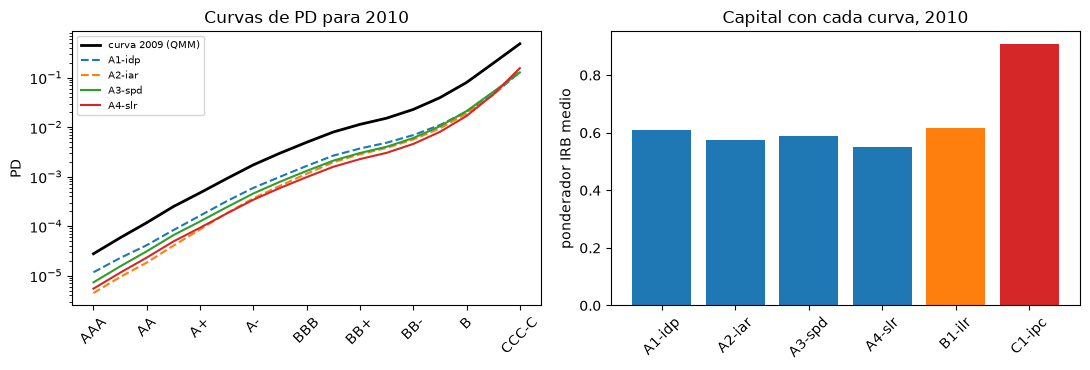

In [10]:
# Dibujar las curvas de PD por grado y los ponderadores de riesgo por enfoque para 2010
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
left.plot(range(len(grades)), curve0, color="black", linewidth=2, label="curva 2009 (QMM)")
for key, style in (("A1-idp", "--"), ("A2-iar", "--"), ("A3-spd", "-"), ("A4-slr", "-")):
    left.plot(range(len(grades)), curves[key], style, label=key)
left.set_yscale("log")
left.set_xticks(range(0, len(grades), 2))
left.set_xticklabels(grades[::2], rotation=45)
left.set_ylabel("PD")
left.set_title("Curvas de PD para 2010")
left.legend(fontsize=7)
keys = list(table[2010])
right.bar(range(len(keys)), [table[2010][k] for k in keys], color=["tab:blue"] * 4 + ["tab:orange", "tab:red"])
right.set_xticks(range(len(keys)))
right.set_xticklabels(keys, rotation=45)
right.set_ylabel("ponderador IRB medio")
right.set_title("Capital con cada curva, 2010")
fig.tight_layout()
plt.show()

## Resultados

- **El modelo de 2009 es una distribución conjunta consistente.** El motor reproduce la PD incondicional versionada (3,99%), el perfil de incumplimiento (a 2e-10) y la razón de precisión (0,8271) desde el perfil y las tasas de incumplimiento por grado. Seis de las 17 tasas crudas son cero, así que una razón de verosimilitud construida con ellas no está definida y la curva debe suavizarse.
- **QMM.** Con alfa = 5,2048 y beta = 2,1613 la curva suavizada alcanza las metas de 2009 e iguala la curva versionada a 1e-10. Da a AAA 0,0028% donde la tasa cruda es 0, a B 8,00% donde la tasa cruda es 9,96%, y crece con el grado.
- **Caso 1, 2010.** La PD del pronóstico es 1,14%, bajo la PD de 2009 de 3,99%. Escalar las PD multiplica cada grado por c_PD = 0,2642 (la mayor PD escalada es 12,8%, propia); la razón de verosimilitud escalada tiene c_LR = 1,4081 dentro de su intervalo 0,0188 a 1,5494, con residuo 0 en la ecuación 4.8a. Los cuatro enfoques dan la PD del pronóstico bajo el perfil de 2010 y difieren en la forma: sus razones de precisión son 0,7935 (perfil de incumplimiento invariante), 0,8271 (mantenida de 2009), 0,8100 (PD escaladas) y 0,8451 (razón de verosimilitud escalada). Cada curva iguala la versionada.
- **Cuando se sabe menos.** Con solo la PD (caso 2), la razón de verosimilitud invariante da 1,55% bajo el perfil observado de 2010 en vez del 1,14% que se le dio: sin el perfil no puede ser consistente. Llevar la curva de 2009 sin cambios (caso 3) pronostica 4,32% frente a un 1,14% observado, 3,8 veces.
- **La prueba del perfil de incumplimiento implicado.** En 2010 el perfil de incumplimiento invariante (p = 0,046) y las PD escaladas (p = 0,043) quedan en ámbar y la razón de verosimilitud escalada (p = 0,112) y la razón de precisión invariante (p = 0,079) en verde; en 2011 los nueve enfoques quedan en verde (p de 0,37 a 0,89). Los valores p vienen de 100.000 simulaciones con un error Monte Carlo de cerca de 0,0007.
- **Capital.** El ponderador IRB medio de la cartera de 2010 es 55,0% con la razón de verosimilitud escalada, 57,3% con la razón de precisión invariante, 58,8% con PD escaladas, 60,9% con el perfil de incumplimiento invariante y 90,7% con la curva de 2009 sin cambios: 64,8% más capital que la razón de verosimilitud escalada en 2010 y 83,3% en 2011; los cuatro enfoques del caso 1 se dispersan 10,7% en 2010 y 8,3% en 2011. El recálculo iguala el impacto versionado.
- **Contra lo impreso.** Las cuatro curvas de la Tabla 7 quedan a menos de 0,0005 puntos porcentuales de los valores impresos de Tasche en todo grado. La mayor diferencia de la Tabla 5 es 0,0013 puntos en CCC-C (impreso 48,355, recalculado 48,3537; la comparación versionada redondea a los tres decimales impresos y tiene una diferencia de 0,001, su tolerancia). Los valores p versionados (4,58, 7,91, 4,25 y 11,15%) quedan a unos 0,25 puntos de los impresos 4,6, 8,0, 4,0 y 11,3 (sus errores Monte Carlo son de 0,06 a 0,10 puntos; el 4,0 contra 4,25 de las PD escaladas es la diferencia mayor).

Lo que este cuaderno no muestra: la comparación de los nueve enfoques sobre la PD pronosticada frente a la observada (cuaderno 09), ni cómo un error de calibración se propaga por la fórmula IRB (cuaderno 07).

## Resumen

- Un modelo de calificación es una distribución conjunta de grado e incumplimiento; la curva de PD, los dos perfiles condicionales y la razón de verosimilitud son descripciones equivalentes y el motor verifica las identidades.
- Una curva con tasas cero se suaviza por QMM antes de llevarla a un año nuevo.
- Con el perfil y la PD del pronóstico conocidos, cuatro enfoques llevan la curva; difieren en lo que mantienen invariante y sus curvas difieren en la forma, no en la PD del pronóstico. Escalar las PD es lo más simple y lo menos defendible.
- Mantener la curva vieja sin cambios pronostica una PD 3,8 veces la observada y cuesta entre 65% y 83% más capital que la razón de verosimilitud escalada.
- La prueba del perfil de incumplimiento ve la forma de una curva, no su nivel; cada recálculo se compara con el artefacto versionado y con las tablas impresas de Tasche.

**Qué probar después.** Reemplaza la PD del pronóstico del Paso 3 por la PD de 2009 y mira qué enfoques mantienen la curva y cuáles la mueven; luego lee el cuaderno 06.

## Referencias

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, ecuaciones 3.5, 3.7, 3.8, 4.2 a 4.15 y apéndice A, Tablas 6 a 8; arXiv 1212.3716. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo (LGD, vencimiento y piso de PD). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Elkan, C. (2001), The foundations of cost-sensitive learning, IJCAI, para el cambio de tasa base (ecuación 4.11).
- Pearson, K. (1900), On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling, Philosophical Magazine 50(302), 157-175.